<a href="https://colab.research.google.com/github/KavinMadusanka/fake-news-detection/blob/feat%2Fmodels/notebooks/model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1: GitHub Repository Configuration and Branch Setup

In this step, we configure Git credentials (user name and email), clone the main project repository from GitHub,  
and create a new feature branch for our work.  

In [1]:
# Configure Git identity
!git config --global user.email "indrachapavithanage306@gmail.com"
!git config --global user.name "SandaminiI"

# Define repository information
REPO = "fake-news-detection"
OWNER = "KavinMadusanka"
TOKEN = "token"

!git clone https://{TOKEN}@github.com/{OWNER}/{REPO}.git
%cd /content/{REPO}

# Create a new feature branch
#BRANCH = "feat/models"
!git checkout -b feat/models

Cloning into 'fake-news-detection'...
remote: Enumerating objects: 99, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (90/90), done.
remote: Total 99 (delta 47), reused 28 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (99/99), 2.06 MiB | 12.03 MiB/s, done.
Resolving deltas: 100% (47/47), done.
/content/fake-news-detection
Switched to a new branch 'feat/models'


## Step 2: Environment Setup and Library Installation

In [2]:
!pip -q install pandas numpy scikit-learn tensorflow torch transformers matplotlib

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import os, pathlib

os.makedirs("data/processed", exist_ok=True)
os.makedirs("results/figs", exist_ok=True)

!ls -lah data/processed

total 8.0K
drwxr-xr-x 2 root root 4.0K Oct 11 09:03 .
drwxr-xr-x 3 root root 4.0K Oct 11 09:03 ..


## Step 3: Upload and Load the Dataset

In [3]:
# Install gdown (only once)
!pip install -q gdown

import os

# Create folder for data
os.makedirs("data/processed", exist_ok=True)

# File IDs
train_id = "1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA"
val_id   = "1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA"
test_id  = "1mxZ3JX9xxF_lwRXlnZBYBlI1jqZpF00C"

# Download datasets (updated syntax — no warning)
!gdown https://drive.google.com/uc?id={train_id} -O data/processed/train.csv
!gdown https://drive.google.com/uc?id={val_id}   -O data/processed/val.csv
!gdown https://drive.google.com/uc?id={test_id}  -O data/processed/test.csv

# Verify downloaded files
!ls -lh data/processed

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA
To: /content/fake-news-detection/data/processed/train.csv
100% 68.1M/68.1M [00:01<00:00, 58.8MB/s]
/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA
To: /content/fake-news-detection/data/processed/val.csv
100% 68.1M/68.1M [00:00<00:00, 262MB/s]
/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to us

In [4]:
import pandas as pd

train = pd.read_csv("data/processed/train.csv")
val   = pd.read_csv("data/processed/val.csv")
test  = pd.read_csv("data/processed/test.csv")

print("Train shape:", train.shape)
print("Val shape:", val.shape)
print("Test shape:", test.shape)
train.head()


Train shape: (37554, 2)
Val shape: (37554, 2)
Test shape: (4489, 3)


,text_clean,label
0,kenya police shoot dead two opposition protest...,0
1,angry cruz kicks young boy rally disruptive su...,1
2,region must pressure south sudan leaders end c...,0
3,names revealed top donor popular actress behin...,1
4,holy moly rebel media uncovers illegal usa can...,1


**If Manually Uploading files**

In this step, upload the preprocessed CSV files (`train.csv`, `val.csv`, and `test.csv`)  
from the local system to the Colab environment using the `files.upload()` function.

Then, we:
- Move the uploaded files into the `data/processed/` directory.
- Load the datasets into Pandas DataFrames for analysis and model training.
- Display the shapes of the three datasets to confirm successful loading.

In [ ]:
from google.colab import files
uploaded = files.upload()    # choose train.csv, val.csv, test.csv

import os
os.makedirs("data/processed", exist_ok=True)

# Move uploaded files to the processed data directory
!mv train.csv data/processed/train.csv
!mv val.csv data/processed/val.csv
!mv test.csv data/processed/test.csv

# Verify that the files exist in the correct folder
!ls data/processed

# Load datasets into pandas DataFrames
train = pd.read_csv("data/processed/train.csv")
val   = pd.read_csv("data/processed/val.csv")
test  = pd.read_csv("data/processed/test.csv")

print(train.shape, val.shape, test.shape)

## Step 4: Model Training and Performance Comparison  

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

# Data Preparation
tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(train['text_clean'])

# Convert text to sequences
train_seq = tokenizer.texts_to_sequences(train['text_clean'])
val_seq   = tokenizer.texts_to_sequences(val['text_clean'])
test_seq  = tokenizer.texts_to_sequences(test['text_clean'])

# Pad sequences to same length
max_len = 300
X_train_pad = pad_sequences(train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(test_seq, maxlen=max_len)


In [7]:
# Helper function for evaluating models
def eval_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    print(f"{name} → Accuracy:{acc:.4f}, F1:{f1:.4f}")
    return acc, f1

# Model 1 - LSTM

In [9]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# LSTM model Architecture
model = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    LSTM(128, dropout=0.3, recurrent_dropout=0.3),
    Dense(1, activation='sigmoid')
])

#compile the model
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

#Train the model
history = model.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# Predict and evaluate
pred_lstm = (model.predict(X_test_pad) > 0.5).astype('int32')

# Initialize res if it doesn't exist
if 'res' not in locals():
    res = {}

# Log Results
res['LSTM'] = eval_model('LSTM', test['label'], pred_lstm)

Epoch 1/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 610s 2s/step - accuracy: 0.9014 - loss: 0.2455 - val_accuracy: 0.9901 - val_loss: 0.0336
Epoch 2/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 618s 2s/step - accuracy: 0.9860 - loss: 0.0460 - val_accuracy: 0.9942 - val_loss: 0.0214
Epoch 3/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 605s 2s/step - accuracy: 0.9924 - loss: 0.0267 - val_accuracy: 0.9971 - val_loss: 0.0106
141/141 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step
LSTM → Accuracy:0.9831, F1:0.9838


**Plot learning curves**

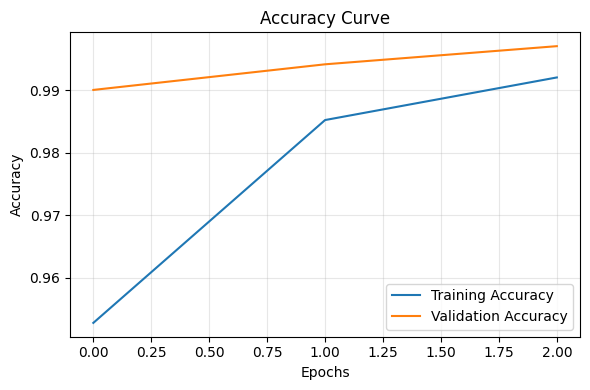

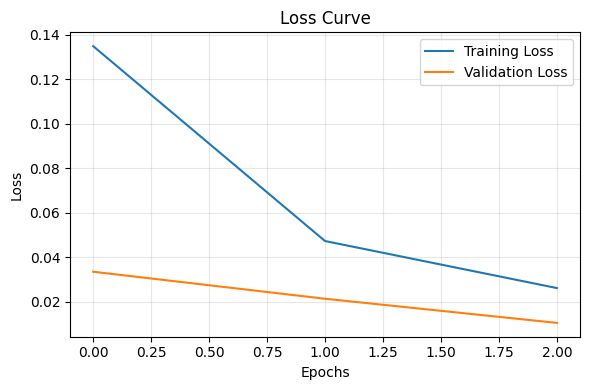

total 1.2M
-rw-r--r-- 1 root root  17K Oct 11 09:03 label_dist_train.png
-rw-r--r-- 1 root root  19K Oct 11 09:03 len_hist_train.png
-rw-r--r-- 1 root root  64K Oct 11 10:40 lstm_accuracy_curve.png
-rw-r--r-- 1 root root  67K Oct 11 10:40 lstm_loss_curve.png
-rw-r--r-- 1 root root  17K Oct 11 09:03 model_comparison.png
-rw-r--r-- 1 root root  13K Oct 11 09:03 tfidf_logreg_performance.png
-rw-r--r-- 1 root root  42K Oct 11 09:03 top_unigrams.png
-rw-r--r-- 1 root root 444K Oct 11 09:03 wc_fake.png
-rw-r--r-- 1 root root 463K Oct 11 09:03 wc_real.png


In [11]:
# Plot & save training curves (LSTM)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# some TF/Keras versions use 'acc' instead of 'accuracy' – handle both
hist = history.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy")
plt.plot(hist[val_acc_key], label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/lstm_accuracy_curve.png", dpi=200)
plt.show()

# Loss curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss")
plt.plot(hist["val_loss"], label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/lstm_loss_curve.png", dpi=200)
plt.show()

# Optional: quick confirmation
!ls -lh results/figs | tail -n +1

**Check the generalization gap**

In [12]:
train_acc = hist[acc_key][-1]
val_acc   = hist[val_acc_key][-1]
train_loss = hist["loss"][-1]
val_loss   = hist["val_loss"][-1]

print(f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | Gap: {train_acc - val_acc:+.4f}")
print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Gap: {val_loss - train_loss:+.4f}")


Train Acc: 0.9921 | Val Acc: 0.9971 | Gap: -0.0050
Train Loss: 0.0262 | Val Loss: 0.0106 | Gap: -0.0157


# Model 2 - Bi LSTM

In [24]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout

#Bi LSTM Model Architecture
model_bilstm = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    Bidirectional(LSTM(128, dropout=0.3, recurrent_dropout=0.3)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

#Compile the model
model_bilstm.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

#Train the model
history_bilstm = model_bilstm.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# Evaluate the model
pred_bilstm = (model_bilstm.predict(X_test_pad) > 0.5).astype('int32')

# Initialize res if it doesn't exist
if 'res' not in locals():
    res = {}

# Log Results
res['BiLSTM'] = eval_model('BiLSTM', test['label'], pred_bilstm)

Epoch 1/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 1265s 4s/step - accuracy: 0.8969 - loss: 0.2441 - val_accuracy: 0.9881 - val_loss: 0.0388
Epoch 2/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 1235s 4s/step - accuracy: 0.9846 - loss: 0.0493 - val_accuracy: 0.9920 - val_loss: 0.0263
Epoch 3/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 1201s 4s/step - accuracy: 0.9895 - loss: 0.0325 - val_accuracy: 0.9923 - val_loss: 0.0225
141/141 ━━━━━━━━━━━━━━━━━━━━ 32s 220ms/step
BiLSTM → Accuracy:0.9771, F1:0.9780


**Plot learning curves**

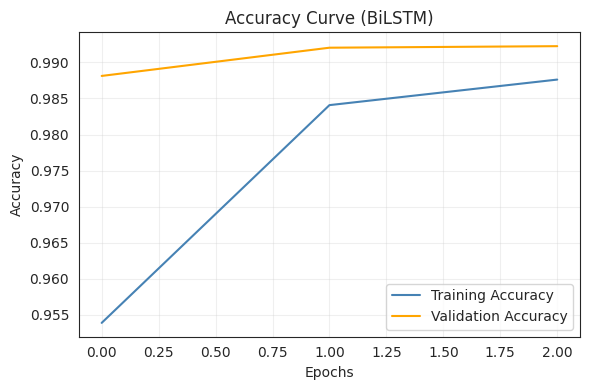

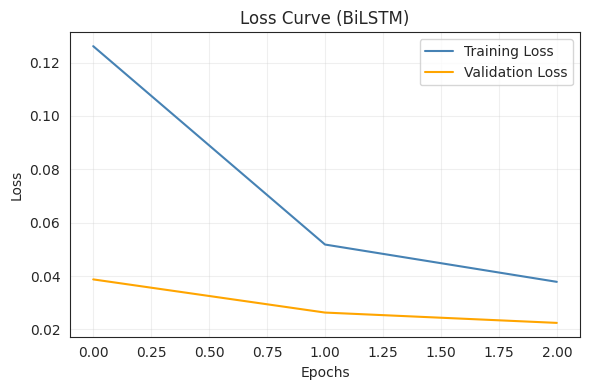

In [25]:
# Plot & save training curves (BiLSTM)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# Extract training history
hist = history_bilstm.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy Curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy", color='steelblue')
plt.plot(hist[val_acc_key], label="Validation Accuracy", color='orange')
plt.title("Accuracy Curve (BiLSTM)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/bilstm_accuracy_curve.png", dpi=200)
plt.show()

# Loss Curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss", color='steelblue')
plt.plot(hist["val_loss"], label="Validation Loss", color='orange')
plt.title("Loss Curve (BiLSTM)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/bilstm_loss_curve.png", dpi=200)
plt.show()

# Model 3 - RNN

In [15]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

# Model Architecture
model_rnn = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    SimpleRNN(128, activation='tanh', dropout=0.3, recurrent_dropout=0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# Compile the Model
model_rnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train Model
history_rnn = model_rnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# Evaluate on Test Set
pred_rnn = (model_rnn.predict(X_test_pad) > 0.5).astype('int32')

# Initialize res if it doesn't exist
if 'res' not in locals():
    res = {}

# Log Results
res['SimpleRNN'] = eval_model('SimpleRNN', test['label'], pred_rnn)

Epoch 1/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 167s 556ms/step - accuracy: 0.5812 - loss: 0.6679 - val_accuracy: 0.7962 - val_loss: 0.4940
Epoch 2/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 155s 528ms/step - accuracy: 0.7249 - loss: 0.5214 - val_accuracy: 0.7918 - val_loss: 0.4873
Epoch 3/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 156s 532ms/step - accuracy: 0.7288 - loss: 0.5097 - val_accuracy: 0.7790 - val_loss: 0.4379
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step
SimpleRNN → Accuracy:0.7677, F1:0.7143


**Plot learning curves**

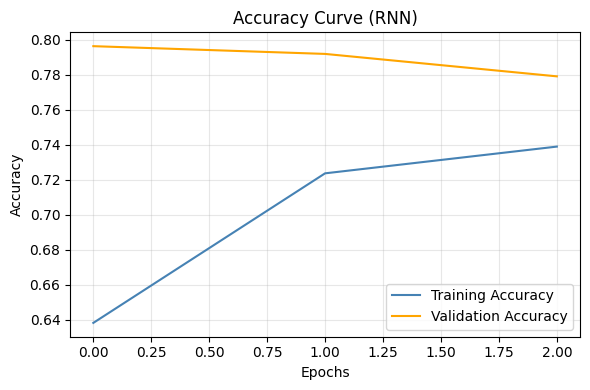

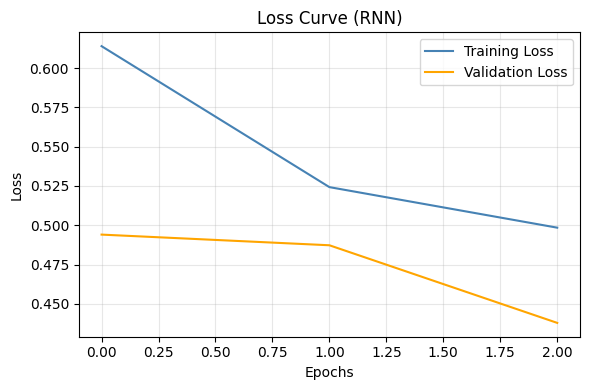

In [17]:
# Plot & save training curves (RNN)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# Extract history dictionary
hist = history_rnn.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy Curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy", color='steelblue')
plt.plot(hist[val_acc_key], label="Validation Accuracy", color='orange')
plt.title("Accuracy Curve (RNN)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/rnn_accuracy_curve.png", dpi=200)
plt.show()

# Loss Curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss", color='steelblue')
plt.plot(hist["val_loss"], label="Validation Loss", color='orange')
plt.title("Loss Curve (RNN)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/rnn_loss_curve.png", dpi=200)
plt.show()

**RNN training stability and automatically prevent overfitting or underfitting during training.**

In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
]

history_rnn = model_rnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=12, batch_size=128, callbacks=callbacks, verbose=1
)

# Gap check
hist = history_rnn.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
print(f"Train acc: {hist[acc_key][-1]:.4f} | Val acc: {hist['val_accuracy'][-1]:.4f}")
print(f"Train loss: {hist['loss'][-1]:.4f} | Val loss: {hist['val_loss'][-1]:.4f}")


Epoch 1/12
294/294 ━━━━━━━━━━━━━━━━━━━━ 164s 559ms/step - accuracy: 0.7568 - loss: 0.4715 - val_accuracy: 0.8147 - val_loss: 0.3919 - learning_rate: 0.0010
Epoch 2/12
294/294 ━━━━━━━━━━━━━━━━━━━━ 154s 525ms/step - accuracy: 0.7872 - loss: 0.4350 - val_accuracy: 0.8261 - val_loss: 0.3692 - learning_rate: 0.0010
Epoch 3/12
294/294 ━━━━━━━━━━━━━━━━━━━━ 156s 532ms/step - accuracy: 0.7989 - loss: 0.4197 - val_accuracy: 0.8264 - val_loss: 0.3678 - learning_rate: 0.0010
Epoch 4/12
294/294 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.7931 - loss: 0.4311
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
294/294 ━━━━━━━━━━━━━━━━━━━━ 155s 527ms/step - accuracy: 0.7931 - loss: 0.4311 - val_accuracy: 0.8139 - val_loss: 0.3901 - learning_rate: 0.0010
Epoch 5/12
294/294 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.8015 - loss: 0.4163
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
294/294 ━━━━━━━━━━━━━━━━━━━━ 153s 521ms/step - accuracy: 0.

In [19]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = test['label'].values
y_pred = pred_rnn.ravel()
print(classification_report(y_true, y_pred, target_names=["Real","Fake"]))
print(confusion_matrix(y_true, y_pred))


              precision    recall  f1-score   support

        Real       0.67      1.00      0.80      2142
        Fake       1.00      0.56      0.71      2347

    accuracy                           0.77      4489
   macro avg       0.84      0.78      0.76      4489
weighted avg       0.84      0.77      0.76      4489

[[2142    0]
 [1043 1304]]


# Model 4 - CNN

In [22]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

#CNN model architecture
model_cnn = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

#Compile the model
model_cnn.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

#Train the model
history_cnn = model_cnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# Evaluate
pred_cnn = (model_cnn.predict(X_test_pad) > 0.5).astype('int32')

#Log Results
res['CNN'] = eval_model('CNN', test['label'], pred_cnn)

Epoch 1/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 169s 569ms/step - accuracy: 0.8941 - loss: 0.2478 - val_accuracy: 0.9973 - val_loss: 0.0108
Epoch 2/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 201s 565ms/step - accuracy: 0.9976 - loss: 0.0088 - val_accuracy: 0.9998 - val_loss: 0.0017
Epoch 3/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 202s 565ms/step - accuracy: 0.9999 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 1.3035e-04
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step
CNN → Accuracy:0.9955, F1:0.9957


**Plot learning curves**

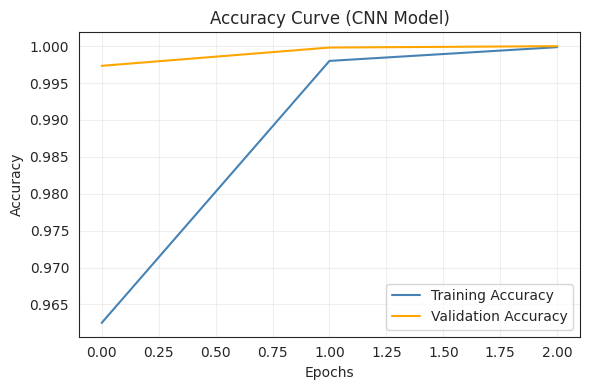

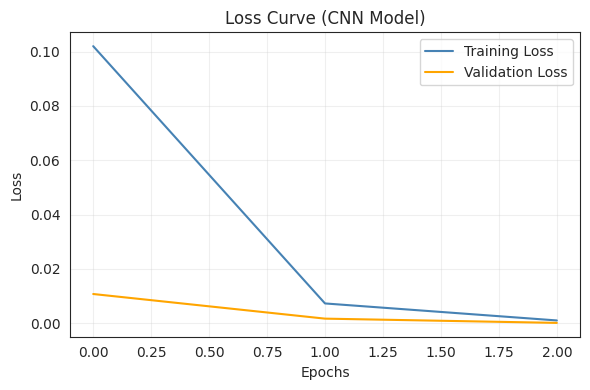

In [23]:
# Plot & save training curves (CNN)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# Extract training history
hist = history_cnn.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy Curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy", color='steelblue')
plt.plot(hist[val_acc_key], label="Validation Accuracy", color='orange')
plt.title("Accuracy Curve (CNN Model)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/cnn_accuracy_curve.png", dpi=200)
plt.show()

# Loss Curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss", color='steelblue')
plt.plot(hist["val_loss"], label="Validation Loss", color='orange')
plt.title("Loss Curve (CNN Model)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/cnn_loss_curve.png", dpi=200)
plt.show()

## Step 5: Compare and Visualize Model Performance


       Model  Accuracy        F1
0       LSTM  0.983070  0.983823
1     BiLSTM  0.977055  0.977977
2  SimpleRNN  0.767654  0.714325
3        CNN  0.995545  0.995739

Saved: results/metrics/model_metrics_deep.csv


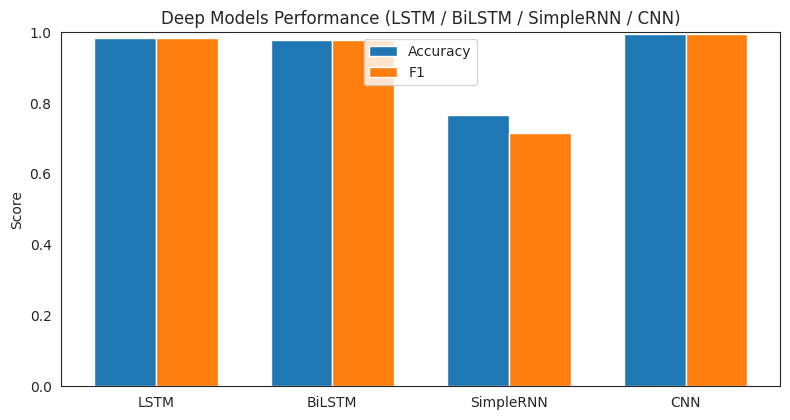

Saved: results/figs/model_comparison_deep.png


In [29]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Ensure output folders exist
os.makedirs('results/metrics', exist_ok=True)
os.makedirs('results/figs', exist_ok=True)

# Pick only the deep-learning models you want, in this order
desired_order = ['LSTM', 'BiLSTM', 'SimpleRNN', 'CNN']

# 'res' should look like: {'LSTM': (acc, f1), 'BiLSTM': (acc, f1), ...}
# Build rows only for keys that actually exist in res
rows = []
for name in desired_order:
    if name in res:
        acc, f1 = res[name]
        rows.append((name, float(acc), float(f1)))

# Safety: if nothing found, raise a friendly error
if not rows:
    raise ValueError("No matching models found in `res`. Make sure you've added LSTM/BiLSTM/SimpleRNN/CNN results to `res`.")

# DataFrame in desired order
df_res = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'F1'])

# (Optional) round for a tidy CSV/print
df_res_rounded = df_res.copy()
df_res_rounded['Accuracy'] = df_res_rounded['Accuracy'].round(6)
df_res_rounded['F1']       = df_res_rounded['F1'].round(6)

# Save & show table
csv_path = 'results/metrics/model_metrics_deep.csv'
df_res_rounded.to_csv(csv_path, index=False)
print(df_res_rounded)
print(f"\nSaved: {csv_path}")

# Plot: Accuracy & F1 side-by-side bars
plt.figure(figsize=(8, 4.3))
x = range(len(df_res))
width = 0.35

plt.bar([i - width/2 for i in x], df_res['Accuracy'], width=width, label='Accuracy')
plt.bar([i + width/2 for i in x], df_res['F1'],       width=width, label='F1')

plt.xticks(x, df_res['Model'])
plt.ylim(0.0, 1.0)
plt.ylabel('Score')
plt.title('Deep Models Performance (LSTM / BiLSTM / SimpleRNN / CNN)')
plt.legend()
plt.tight_layout()

fig_path = 'results/figs/model_comparison_deep.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path}")

## Step 6: Save All Trained Models and Artifacts for Deployment

In this step, we save every trained model, vectorizer, and tokenizer so they can be reused. All files are stored in the `results/models/` directory.

In [26]:
import os
import joblib

# Create directory if not exists
os.makedirs('results/models', exist_ok=True)

# Save Deep Learning Models
# Each model is saved in Keras format (.keras)
# Make sure you already trained them and the variables exist in your notebook
# (model, model_bilstm, model_rnn, model_cnn)

model.save('results/models/lstm_model.keras')           # LSTM
model_bilstm.save('results/models/bilstm_model.keras')  # BiLSTM
model_rnn.save('results/models/simplernn_model.keras')  # RNN
model_cnn.save('results/models/cnn_model.keras')        # CNN

# Save Tokenizer (common across models)
joblib.dump(tokenizer, 'results/models/tokenizer.joblib')

# Verify everything
print("All deep learning models and tokenizer saved in results/models/")
!ls -lh results/models

All deep learning models and tokenizer saved in results/models/
total 129M
-rw-r--r-- 1 root root  33M Oct 11 12:42 bilstm_model.keras
-rw-r--r-- 1 root root  31M Oct 11 12:42 cnn_model.keras
-rw-r--r-- 1 root root  31M Oct 11 12:42 lstm_model.keras
-rw-r--r-- 1 root root  30M Oct 11 12:42 simplernn_model.keras
-rw-r--r-- 1 root root 4.5M Oct 11 12:42 tokenizer.joblib


## Step 7: Backup Models to Google Drive

After successfully training and saving all models, we back them up to Google Drive to ensure the artifacts are safely stored and accessible  
for evaluation.

In [27]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p '/content/drive/MyDrive/fake_news_project/models'
!cp results/models/* '/content/drive/MyDrive/fake_news_project/models/'
print("Models copied to Google Drive.")

Mounted at /content/drive
Models copied to Google Drive.


**Github upload**

In [30]:
!git add -f results/model_metrics.csv \
           results/figs/cnn_accuracy_curve.png \
           results/figs/cnn_loss_curve.png \
           results/figs/lstm_accuracy_curve.png \
           results/figs/lstm_loss_curve.png \
           results/figs/rnn_accuracy_curve.png \
           results/figs/rnn_loss_curve.png \
           results/figs/bilstm_accuracy_curve.png \
           results/figs/bilstm_loss_curve.png \
           results/figs/model_comparison_deep.png

!git commit -m "Model training (LR, SVM, TFIDF_LogReg, LSTM)"
!git push --set-upstream origin feat/models

[feat/models 4ea6586] Model training (LR, SVM, TFIDF_LogReg, LSTM)
 9 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 results/figs/bilstm_accuracy_curve.png
 create mode 100644 results/figs/bilstm_loss_curve.png
 create mode 100644 results/figs/cnn_accuracy_curve.png
 create mode 100644 results/figs/cnn_loss_curve.png
 create mode 100644 results/figs/lstm_accuracy_curve.png
 create mode 100644 results/figs/lstm_loss_curve.png
 create mode 100644 results/figs/model_comparison_deep.png
 create mode 100644 results/figs/rnn_accuracy_curve.png
 create mode 100644 results/figs/rnn_loss_curve.png
fatal: could not read Password for 'https://token@github.com': No such device or address
